# Black-box transfer ASR scatter

Thin driver for `analytics.attacks.transfer_scatter`. Outgoing (source attack potential) vs incoming (target vulnerability) ASR-AUC for black-box transfer only.

**Filter A — inter-model:** exclude self-attacks (`source == target`).

**Filter B — inter-architecture:** additionally exclude same-architecture pairs (e.g. CNN→CNN).

**Filter C — inter-family:** only cross-family pairs (Classical / Hybrid / Quantum); same-family transfers are excluded.

Terminology: low incoming ASR is **target-side transfer resistance**, not general robustness. Low outgoing ASR is **weak transferable source potential**. White-box ASR is separate.

For `robust_accuracy`, values are typically ~0.05–0.6; the default 40–100% axis clip auto-expands to the data range when needed.

In [1]:
import sys
from pathlib import Path

_project_root = Path.cwd().resolve()
while _project_root != _project_root.parent and not (_project_root / "src" / "analytics").is_dir():
    _project_root = _project_root.parent
if not (_project_root / "src" / "analytics").is_dir():
    raise FileNotFoundError(
        "Could not find the project root (expected src/analytics/). "
        "Set the notebook working directory to the QB-PIER repo root."
    )
_src = _project_root / "src"
if str(_src) not in sys.path:
    sys.path.insert(0, str(_src))

from analytics.notebook_setup import notebook_paths

project_root, TRAINING_ROOT, ATTACK_EXPERIMENT_DIR, OUT, _src = notebook_paths(
    "transfer_scatter", start=_project_root
)

In [2]:
from IPython.display import Image, Markdown, display
import pandas as pd

from analytics.attacks import ATTACK_MODEL_BLACKLIST
from analytics.tables.extract_attack import build_pair_metrics
from analytics.attacks import ATTACK_TABLE_METRICS, available_transfer_metrics
from analytics.attacks.transfer_scatter import (
    TransferScatterPlotOptions,
    run_transfer_scatter_report,
)

METRIC = "ASR"  # ASR, robust_accuracy, flip_rate, mean_confidence_drop_all, ...

PLOT_OPTIONS = TransferScatterPlotOptions(
    metric=METRIC,
    xlim=(0.4, 1.0),
    ylim=(0.4, 1.0),
    clip_axes=True,
    show_quadrant_annotations=True,
    show_point_labels=True,
)

# Blacklist (exact paths + VQM no_entangling) applied inside build_pair_metrics.
print("Attack model blacklist:", ATTACK_MODEL_BLACKLIST)

pair_df, per_seed_df = build_pair_metrics(
    attack_dir=ATTACK_EXPERIMENT_DIR,
    output_path=OUT / "pair_metrics.csv",
)
bb = int((pair_df["WB/BB Flag"] == "BB").sum())
wb = int((pair_df["WB/BB Flag"] == "WB").sum())
print(f"Pair metrics: {len(pair_df)} rows (WB={wb}, BB={bb})")
print(f"Models: {pair_df['Source Model'].nunique()} sources")

Attack model blacklist: ('Quantum/VQM/ansatz=no_entangling, qdepth=50',)
Blacklisted rows removed: 2814
Pair metrics: 1089 rows (WB=33, BB=1056)
Models: 33 sources


In [3]:
outputs = run_transfer_scatter_report(pair_df, OUT, plot_options=PLOT_OPTIONS)
for name, path in sorted(outputs.items()):
    print(f"{name}: {path}")

architecture_inter_architecture: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\architecture_inter_architecture.png
architecture_inter_model: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\architecture_inter_model.png
architecture_profile_inter_architecture: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\architecture_profile_inter_architecture.csv
architecture_profile_inter_model: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\architecture_profile_inter_model.csv
interpretation: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\interpretation.md
model_profile_inter_architecture: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\model_profile_inter_architecture.csv
model_profile_inter_model: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\model_profile_inter_model.csv
outliers: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\outliers.md
summary_table: C:\Users\fwilh\Desktop\QB-PIER\outputs\transfer_scatter\summary_table.csv

In [ ]:
summary = pd.read_csv(OUT / "summary_table.csv")
display(summary)

In [ ]:
display(Markdown((OUT / "interpretation.md").read_text(encoding="utf-8")))
display(Markdown((OUT / "outliers.md").read_text(encoding="utf-8")))

### architecture_inter_architecture.png

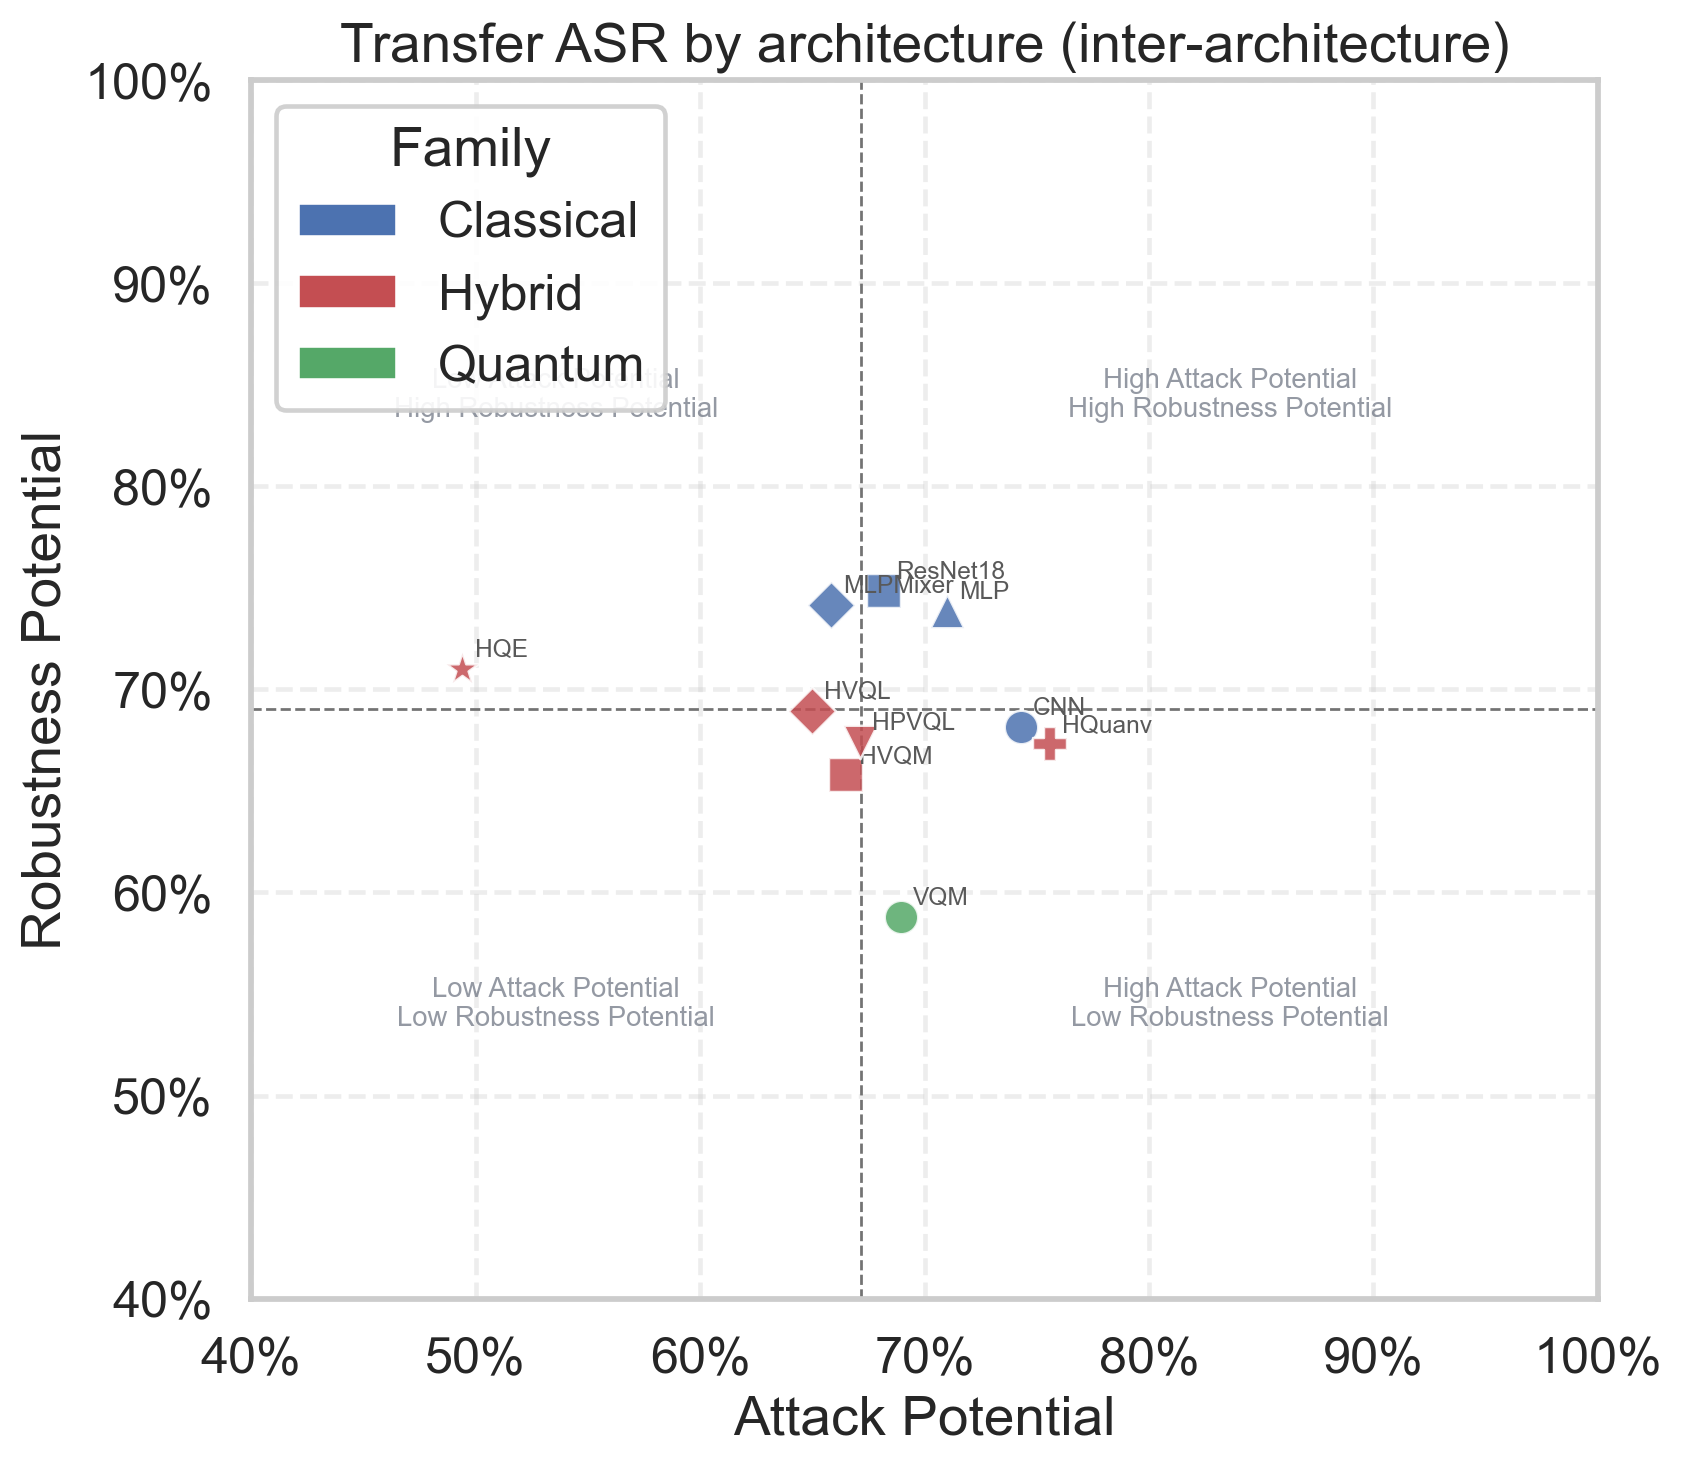

### architecture_inter_model.png

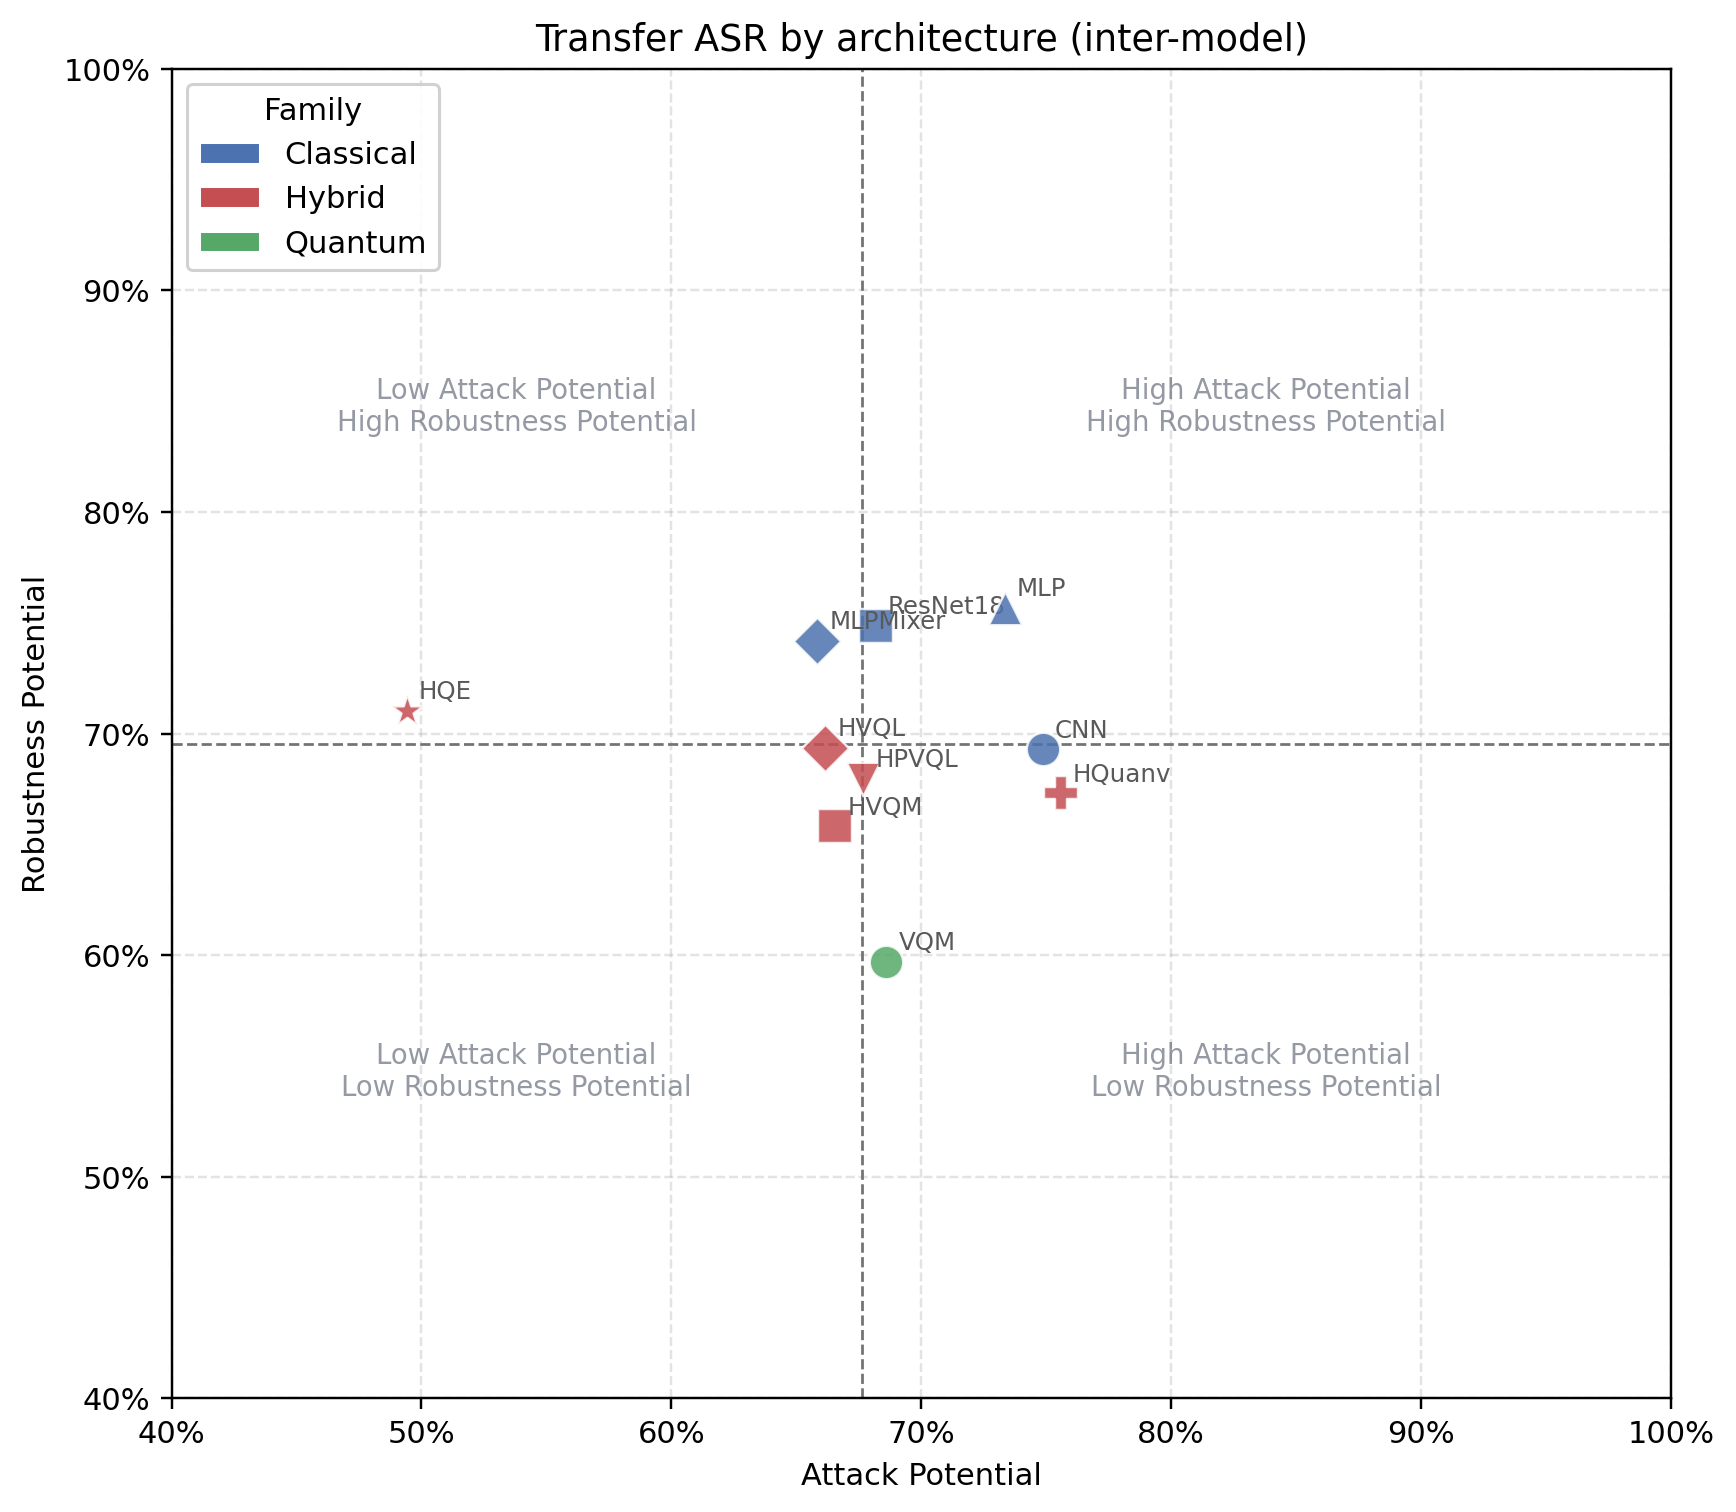

### variant_inter_architecture.png

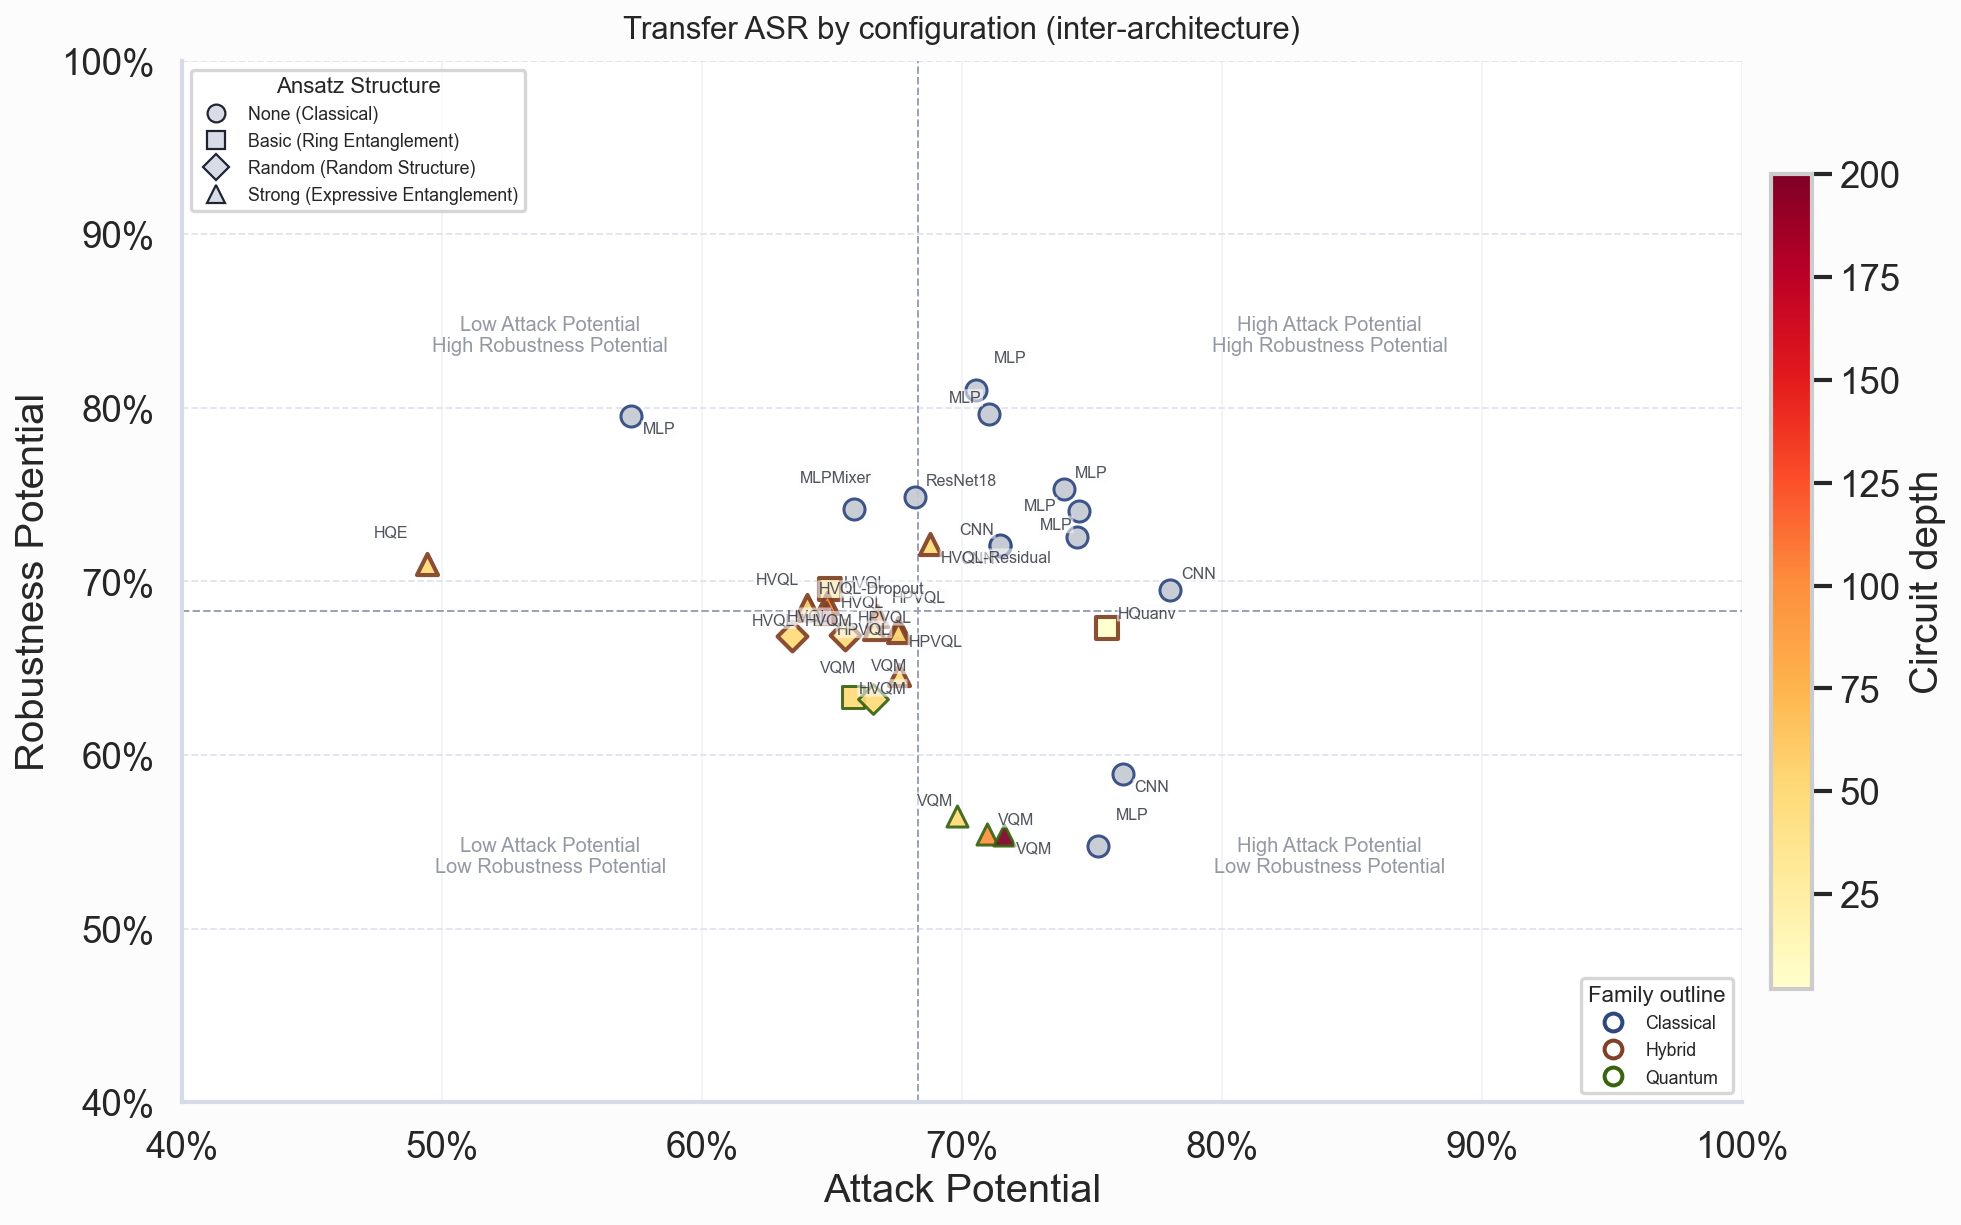

### variant_inter_model.png

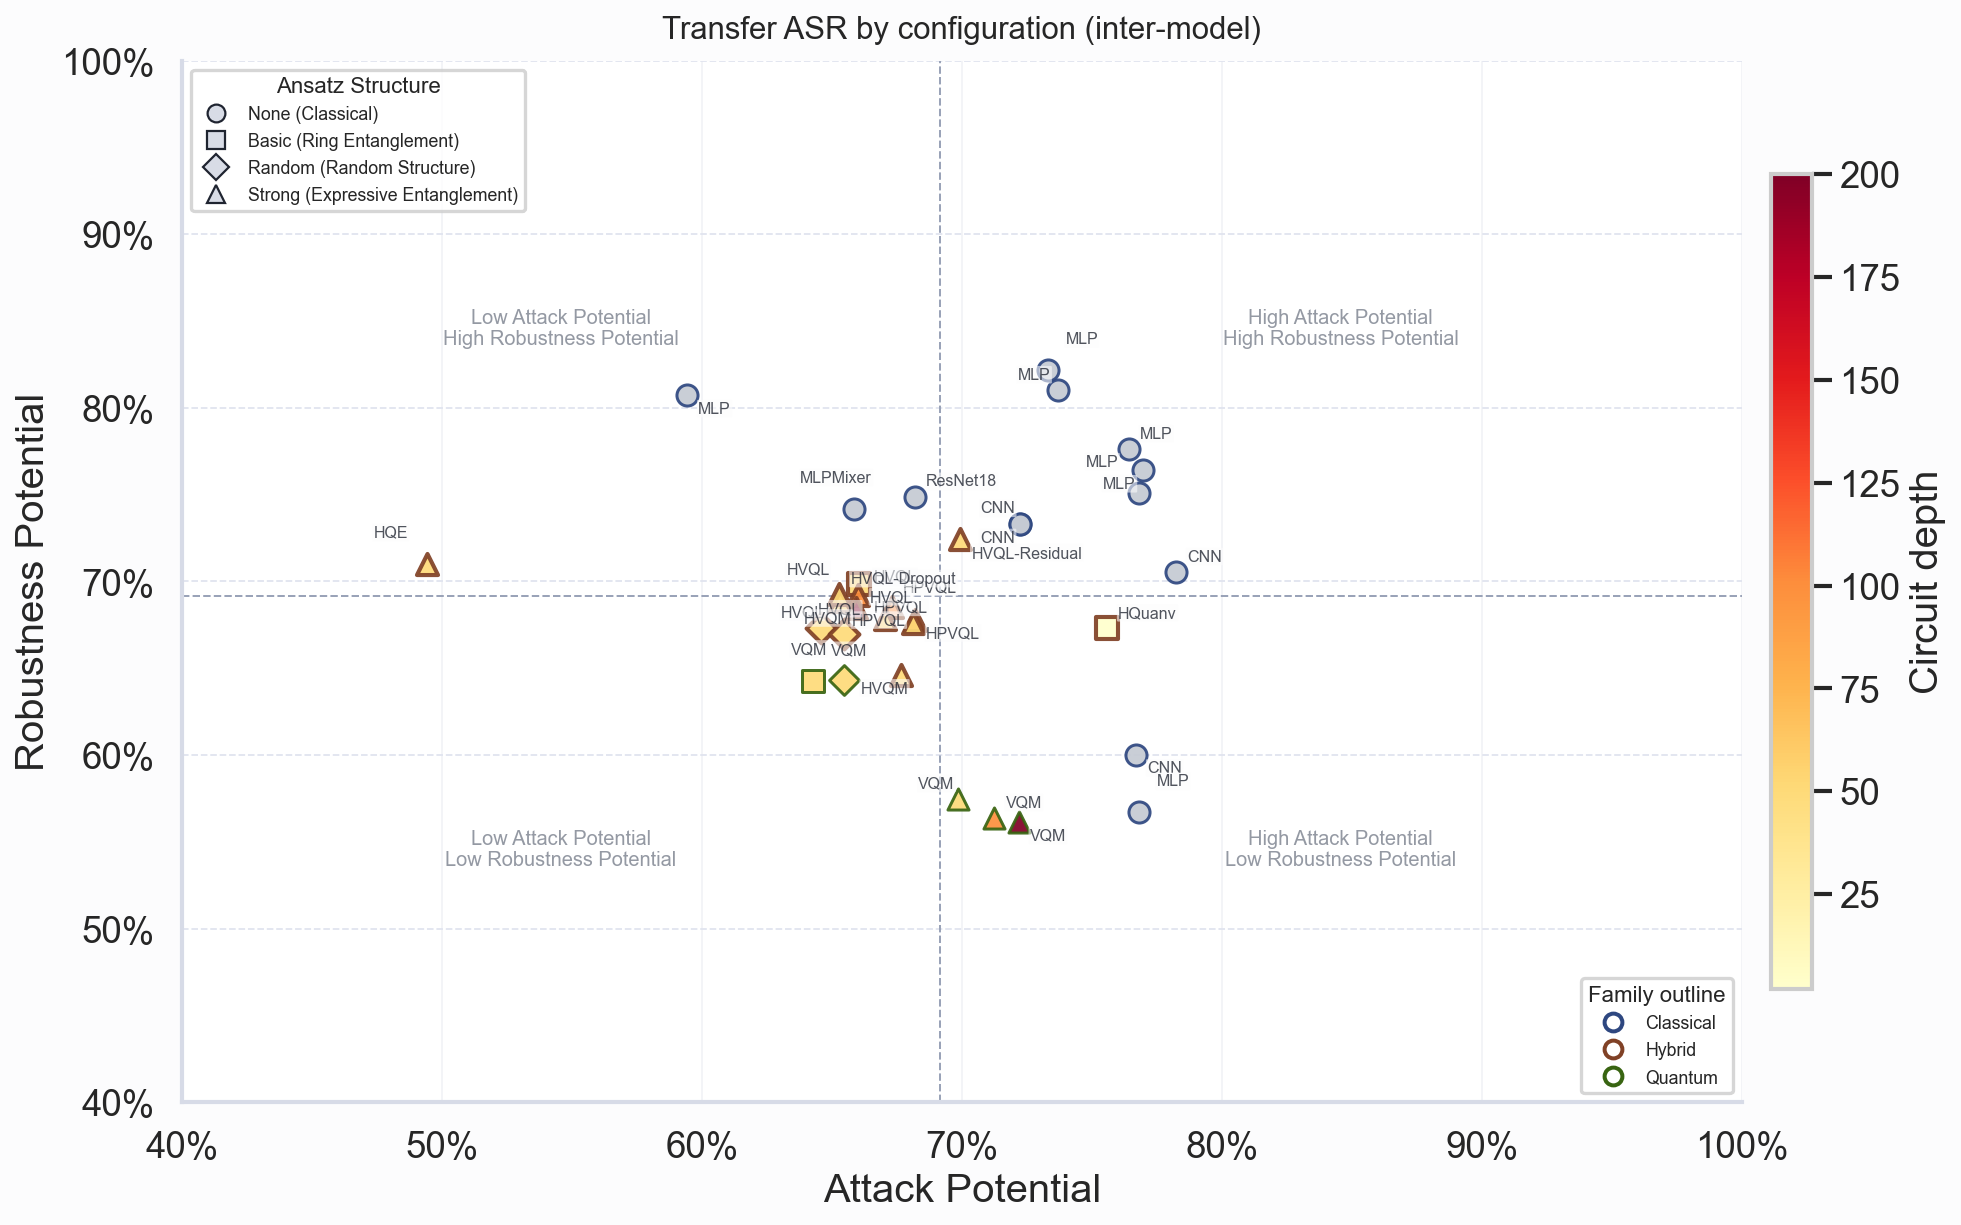

In [4]:
for png in sorted(OUT.glob("*.png")):
    display(Markdown(f"### {png.name}"))
    display(Image(filename=str(png)))